In [5]:
import sys, pathlib
ROOT = pathlib.Path.cwd() if (pathlib.Path.cwd() / 'cartpole.py').exists() else pathlib.Path.cwd().parent
sys.path.insert(0, str(ROOT))

In [9]:
import importlib, cartpole as cp, controllers
importlib.reload(cp); importlib.reload(controllers)
from controllers import lqr_discrete, LQRController, FiniteDiffLQR, run_closed_loop
import numpy as np
import matplotlib.pyplot as plt
P = cp.CartPoleParams(); A, B = cp.analytic_AB(P); dt = 0.02
A_d, B_d = cp.discretize(A, B, dt)
K_d, _ = lqr_discrete(A_d, B_d, np.diag([4.0, 1.0, 25.0, 1.0]), np.array([[0.01]]), dt)
s0 = [0.3, 0, 0.1, 0]

print(f"{'σ':>6} | {'kontrolcü':14s} | {'∫F²dt':>8} | {'θ RMS (son 5 s)':>15} | başarılı?")
for sigma in (0.001, 0.005, 0.02):
    for ad, ctrl, sensor in [
        ("ideal LQR",   LQRController(K_d), None),                                      # gerçek durumu görüyor
        ("sonlu fark",  FiniteDiffLQR(K_d), cp.make_sensor(cp.H_XTHETA, sigma, seed=0)),
    ]:
        with np.errstate(all="ignore"):
            t, S, U = run_closed_loop(ctrl, s0, T=10.0, F_max=10.0, substeps=5, sensor=sensor)
        th_rms = np.sqrt(np.mean(S[len(S) // 2:, 2] ** 2))
        ok = np.all(np.isfinite(S)) and np.abs(S[:, 0]).max() <= 2.4 and abs(S[-1, 2]) < 0.05
        print(f"{sigma:6.3f} | {ad:14s} | {np.sum(U**2) * dt:8.1f} | {th_rms:15.4f} | {ok}")

     σ | kontrolcü      |    ∫F²dt | θ RMS (son 5 s) | başarılı?
 0.001 | ideal LQR      |      5.9 |          0.0000 | True
 0.001 | sonlu fark     |     60.0 |          0.0014 | True
 0.005 | ideal LQR      |      5.9 |          0.0000 | True
 0.005 | sonlu fark     |    523.3 |          0.0140 | True
 0.020 | ideal LQR      |      5.9 |          0.0000 | True
 0.020 | sonlu fark     |    986.7 |         38.4352 | False


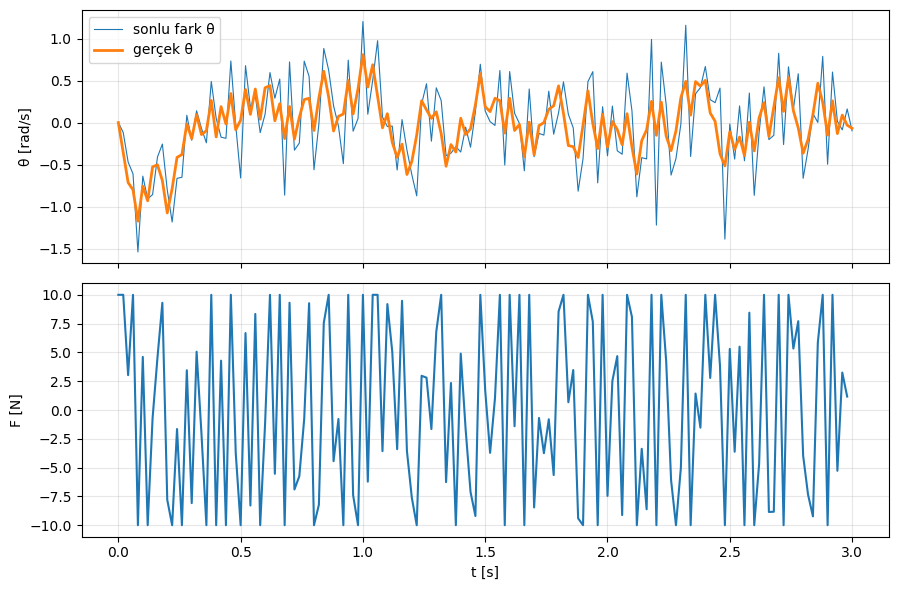

sonlu fark θ̇ hatasının std'si: 0.348   formül √2·σ/dt = 0.354


In [10]:
sensor = cp.make_sensor(cp.H_XTHETA, 0.005, seed=0)
t, S, U = run_closed_loop(FiniteDiffLQR(K_d), s0, T=3.0, F_max=10.0, substeps=5, sensor=sensor)
Z = np.array([cp.H_XTHETA @ s for s in S])                          # gürültüsüz ölçüm...
Z = Z + np.random.default_rng(0).normal(0, 0.005, Z.shape)          # ...+ AYNI gürültü dizisi (seed=0)
thd_fd = np.r_[0, np.diff(Z[:, 1]) / dt]                            # sonlu fark θ̇

fig, ax = plt.subplots(2, 1, figsize=(9, 6), sharex=True)
ax[0].plot(t, thd_fd, lw=0.8, label="sonlu fark θ̇"); ax[0].plot(t, S[:, 3], lw=2, label="gerçek θ̇")
ax[0].set_ylabel("θ̇ [rad/s]"); ax[0].legend()
ax[1].plot(t[:-1], U); ax[1].set_ylabel("F [N]"); ax[1].set_xlabel("t [s]")
for a in ax: a.grid(alpha=0.3)
plt.tight_layout(); plt.show()
print("sonlu fark θ̇ hatasının std'si:", np.std(thd_fd[25:] - S[25:, 3]).round(3), "  formül √2·σ/dt =", round(np.sqrt(2) * 0.005 / dt, 3))

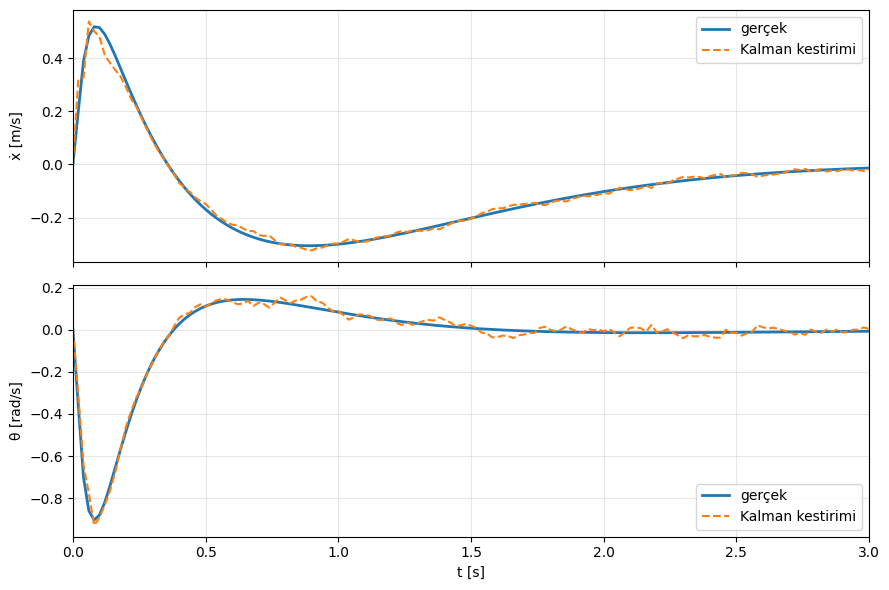

RMS hata [x, ẋ, θ, θ̇]: [0.0017 0.0079 0.0022 0.0164]    (sonlu fark θ̇ hatası: 0.348)
ortalama NEES: 2.05   (tutarlı bir filtre için ≈ 4 = durum sayısı)


In [12]:
importlib.reload(controllers); from controllers import KalmanFilter
H = cp.H_XTHETA; sigma = 0.005; sigma_w = 0.3

# 1) Gerçek yörüngeyi kaydet (ideal LQR) ve gürültülü ölçümleri üret
t, S, U = run_closed_loop(LQRController(K_d), s0, T=10.0, F_max=10.0, substeps=5)
Z = S @ H.T + np.random.default_rng(0).normal(0, sigma, (len(S), 2))

# 2) Filtreyi kaydın üzerinde çalıştır
Q_kf = B_d @ B_d.T * sigma_w**2 + 1e-8 * np.eye(4)        # 1e-8·I: P'nin tekil olmasını önleyen küçük güvenlik payı
R_kf = np.eye(2) * sigma**2
kf = KalmanFilter(A_d, B_d, H, Q_kf, R_kf,
                  s0=[Z[0, 0], 0, Z[0, 1], 0],              # ilk tahmin: ölçülenler ölçümden, hızlar 0
                  P0=np.diag([sigma**2, 1.0, sigma**2, 1.0]))  # hızlardan hiç emin değilim (varyans 1)
for k in range(len(S)):
    if k > 0:
        kf.predict([U[k - 1]])                              # önceki adımda UYGULANAN kuvvet
    kf.update(Z[k])
S_hat = np.array(kf.gecmis_s)

# 3) Gerçek ve kestirim
fig, ax = plt.subplots(2, 1, figsize=(9, 6), sharex=True)
for a, i, ad in [(ax[0], 1, "ẋ [m/s]"), (ax[1], 3, "θ̇ [rad/s]")]:
    a.plot(t, S[:, i], lw=2, label="gerçek"); a.plot(t, S_hat[:, i], "--", label="Kalman kestirimi")
    a.set_ylabel(ad); a.legend(); a.grid(alpha=0.3)
ax[1].set_xlabel("t [s]"); ax[1].set_xlim(0, 3); plt.tight_layout(); plt.show()

hata = S - S_hat
print("RMS hata [x, ẋ, θ, θ̇]:", np.sqrt(np.mean(hata[25:]**2, axis=0)).round(4), "   (sonlu fark θ̇ hatası: 0.348)")

# 4) NEES: filtre kendi belirsizliği konusunda dürüst mü?
nees = np.array([e @ np.linalg.solve(Pk, e) for e, Pk in zip(hata, kf.gecmis_P)])
print("ortalama NEES:", nees[25:].mean().round(2), "  (tutarlı bir filtre için ≈ 4 = durum sayısı)")

In [13]:
from scipy.linalg import solve_discrete_are
sigma = 0.005; sigma_w = 0.3
Q_kf = B_d @ B_d.T * sigma_w**2 + 1e-8 * np.eye(4); R_kf = np.eye(2) * sigma**2
P_kf = solve_discrete_are(A_d.T, H.T, Q_kf, R_kf)                 # ikizlik: A → Aᵀ, B → Hᵀ
L = A_d @ P_kf @ H.T @ np.linalg.inv(H @ P_kf @ H.T + R_kf)       # gözlemci kazancı (H10–11'deki K_e)

# Kapalı döngü (durum s ve kestirim hatası e = s − ŝ):  [s; e]⁺ = [[A−BK, BK], [0, A−LH]] [s; e]
A_kd = np.block([[A_d - B_d @ K_d, B_d @ K_d],
                 [np.zeros((4, 4)), A_d - L @ H]])
oz = lambda M: np.sort_complex(np.linalg.eigvals(M))
print("LQG kapalı döngü :", np.round(oz(A_kd), 4))
print("A − BK  (LQR)    :", np.round(oz(A_d - B_d @ K_d), 4))
print("A − LH  (Kalman) :", np.round(oz(A_d - L @ H), 4))

LQG kapalı döngü : [0.6376+0.j     0.83  -0.1278j 0.83  +0.1278j 0.9052+0.j
 0.9496-0.0284j 0.9496+0.0284j 0.9677-0.0173j 0.9677+0.0173j]
A − BK  (LQR)    : [0.6376+0.j     0.9052+0.j     0.9677-0.0173j 0.9677+0.0173j]
A − LH  (Kalman) : [0.83  -0.1278j 0.83  +0.1278j 0.9496-0.0284j 0.9496+0.0284j]


In [17]:
importlib.reload(controllers); from controllers import LQGController, KalmanFilter

def lqg_kur(sigma, sigma_w=0.3):
    Qk = B_d @ B_d.T * sigma_w**2 + 1e-8 * np.eye(4); Rk = np.eye(2) * sigma**2
    kf = KalmanFilter(A_d, B_d, H, Qk, Rk, s0=[0, 0, 0, 0], P0=np.diag([sigma**2, 1.0, sigma**2, 1.0]))
    return LQGController(K_d, kf)

def olc(ctrl_yap, sigma, seed):
    sensor = None if sigma is None else cp.make_sensor(H, sigma, seed=seed)
    with np.errstate(all="ignore"):
        t, S, U = run_closed_loop(ctrl_yap(), s0, T=10.0, F_max=10.0, substeps=5, sensor=sensor)
    ok = np.all(np.isfinite(S)) and np.abs(S[:, 0]).max() <= 2.4 and abs(S[-1, 2]) < 0.05
    return np.sum(U**2) * dt, ok

print(f"{'σ':>6} | {'kontrolcü':18s} | {'başarı':>6} | {'medyan ∫F²':>10}")
for sigma in (0.005, 0.01, 0.02):
    for ad, yap in [("sonlu fark",          lambda: FiniteDiffLQR(K_d)),
                    ("LQG (σ_w = 0.3)",     lambda: lqg_kur(sigma, 0.3)),
                    ("LQG (σ_w = 1.0)",     lambda: lqg_kur(sigma, 1.0))]:
        r = [olc(yap, sigma, seed) for seed in range(10)]
        print(f"{sigma:6.3f} | {ad:18s} | {sum(o for _, o in r):3d}/10 | {np.median([f for f, _ in r]):10.1f}")

     σ | kontrolcü          | başarı | medyan ∫F²
 0.005 | sonlu fark         |  10/10 |      549.8
 0.005 | LQG (σ_w = 0.3)    |  10/10 |        8.4
 0.005 | LQG (σ_w = 1.0)    |  10/10 |       12.6
 0.010 | sonlu fark         |   6/10 |      755.2
 0.010 | LQG (σ_w = 0.3)    |   8/10 |       36.2
 0.010 | LQG (σ_w = 1.0)    |  10/10 |       19.1
 0.020 | sonlu fark         |   0/10 |      976.2
 0.020 | LQG (σ_w = 0.3)    |   1/10 |      109.8
 0.020 | LQG (σ_w = 1.0)    |  10/10 |       46.3
